In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

**Load and Merge Data**

In [3]:
customers = pd.read_csv("Desktop/Cleaned_Customers.csv")
orders = pd.read_csv("Desktop/Cleaned_Orders.csv")

master_data = orders.merge(customers, on="customer_id", how="left")
master_data["NetRevenue"] = master_data["order_amount"] - master_data["discount"]
master_data["discount_pct"] = (
    master_data["discount"] / master_data["order_amount"]
) * 100

 **Segment-Level Discount & Revenue Analysis**

In [4]:
segment_summary = (
    master_data.groupby("customer_segment")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "count"),
        delivered_orders=(
            "order_status",
            lambda x: (x.str.strip().str.title() == "Delivered").sum(),
        ),
        gross_revenue=("order_amount", "sum"),
        realized_revenue=(
            "NetRevenue",
            lambda x: x[
                master_data.loc[
                    x.index, "order_status"
                ].str.strip().str.title()
                == "Delivered"
            ].sum(),
        ),
        total_discount=("discount", "sum"),
        aov=("order_amount", "mean"),
        avg_discount=("discount", "mean"),
    )
    .reset_index()
)

segment_summary["effective_discount_rate"] = (
    segment_summary["total_discount"] / segment_summary["gross_revenue"]
) * 100
segment_summary["order_frequency"] = (
    segment_summary["total_orders"] / segment_summary["total_customers"]
)

print("=== CUSTOMER SEGMENT PERFORMANCE ===")
print(segment_summary.to_string(index=False))

=== CUSTOMER SEGMENT PERFORMANCE ===
customer_segment  total_customers  total_orders  delivered_orders  gross_revenue  realized_revenue  total_discount         aov  avg_discount  effective_discount_rate  order_frequency
             New                4             5                 4        4230.79           3751.32             125  846.158000     25.000000                 2.954531         1.250000
         Premium                8            19                16       19734.59          14472.79             540 1038.662632     28.421053                 2.736312         2.375000
         Regular                9            24                16       22938.44          13694.77             910  955.768333     37.916667                 3.967140         2.666667
         Unknown                1             2                 2         935.91            915.91              20  467.955000     10.000000                 2.136958         2.000000


**Discount Tier Impact Analysis (Basket Size vs. Margin)**

In [6]:
bins = [-1, 0, 25, 50, 75, 1000]
labels = ["0 (No Discount)", "1 - 25", "26 - 50", "51 - 75", "75+"]
master_data["discount_bracket"] = pd.cut(
    master_data["discount"], bins=bins, labels=labels
)

discount_tier_analysis = (
    master_data.groupby("discount_bracket", observed=False)
    .agg(
        order_count=("order_id", "count"),
        avg_basket_size=("order_amount", "mean"),
        avg_net_revenue=("NetRevenue", "mean"),
        total_gross_revenue=("order_amount", "sum"),
        total_net_revenue=("NetRevenue", "sum"),
        total_discounts_given=("discount", "sum"),
    )
    .reset_index()
)

# Correlation between discount amount and order basket size
correlation = master_data["discount"].corr(master_data["order_amount"])
print(
    f"\nCorrelation between Discount and Basket Size (Order Amount): {correlation:.3f}"
)

print("\n=== DISCOUNT BRACKET ANALYSIS ===")
print(discount_tier_analysis.to_string(index=False))


Correlation between Discount and Basket Size (Order Amount): -0.061

=== DISCOUNT BRACKET ANALYSIS ===
discount_bracket  order_count  avg_basket_size  avg_net_revenue  total_gross_revenue  total_net_revenue  total_discounts_given
 0 (No Discount)           24       996.804167       996.804167             23923.30           23923.30                      0
          1 - 25            6       926.341667       906.341667              5558.05            5438.05                    120
         26 - 50            7       989.418571       939.418571              6925.93            6575.93                    350
         51 - 75            7       726.172857       651.172857              5083.21            4558.21                    525
             75+            6      1058.206667       958.206667              6349.24            5749.24                    600


 **Visualizations**

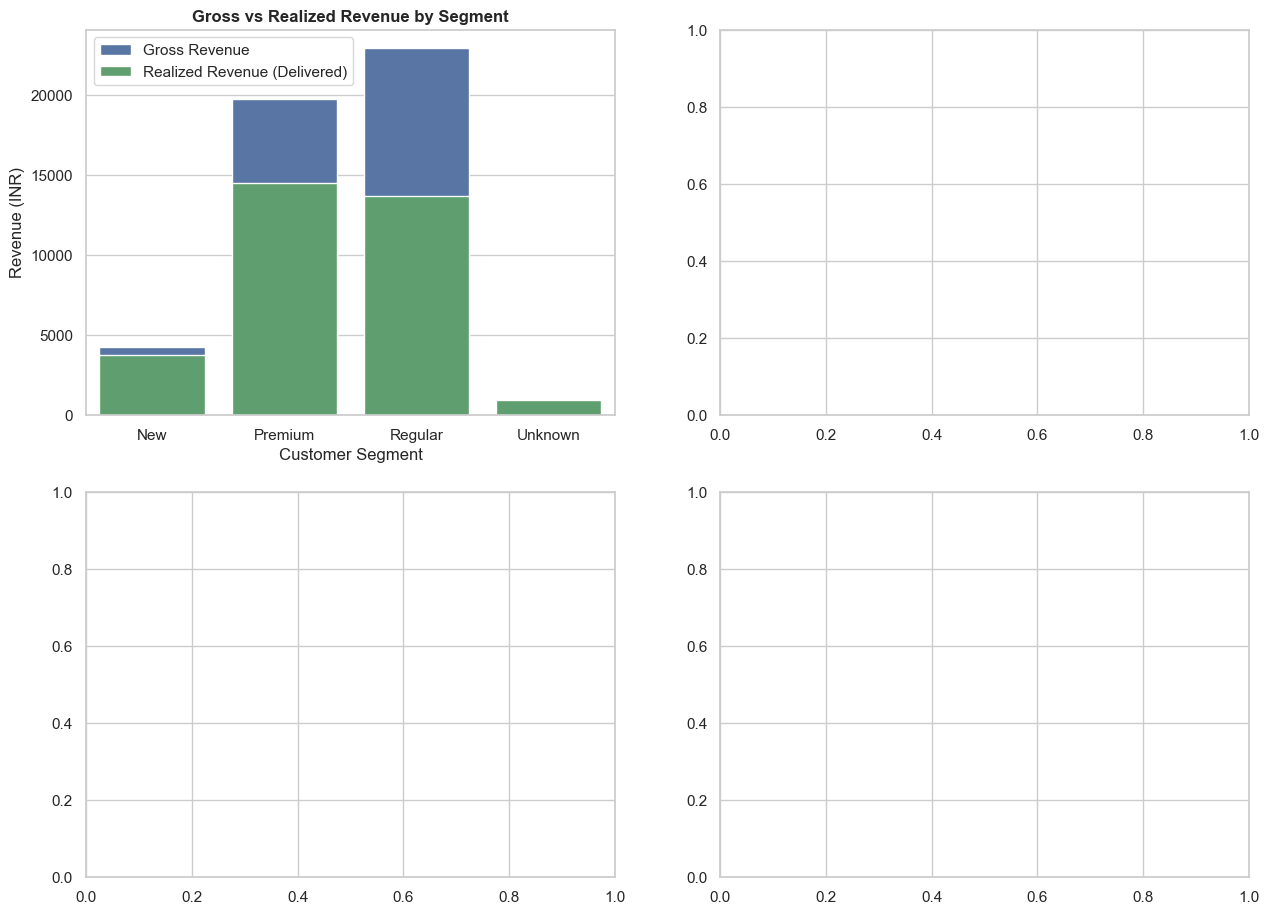

In [15]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Chart 1: Gross vs Realized Revenue by Segment
sns.barplot(
    data=segment_summary,
    x="customer_segment",
    y="gross_revenue",
    color="#4C72B0",
    label="Gross Revenue",
    ax=axes[0, 0],
)
sns.barplot(
    data=segment_summary,
    x="customer_segment",
    y="realized_revenue",
    color="#55A868",
    label="Realized Revenue (Delivered)",
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    "Gross vs Realized Revenue by Segment", fontsize=12, fontweight="bold"
)
axes[0, 0].set_ylabel("Revenue (INR)")
axes[0, 0].set_xlabel("Customer Segment")
axes[0, 0].legend()

(2, 2)


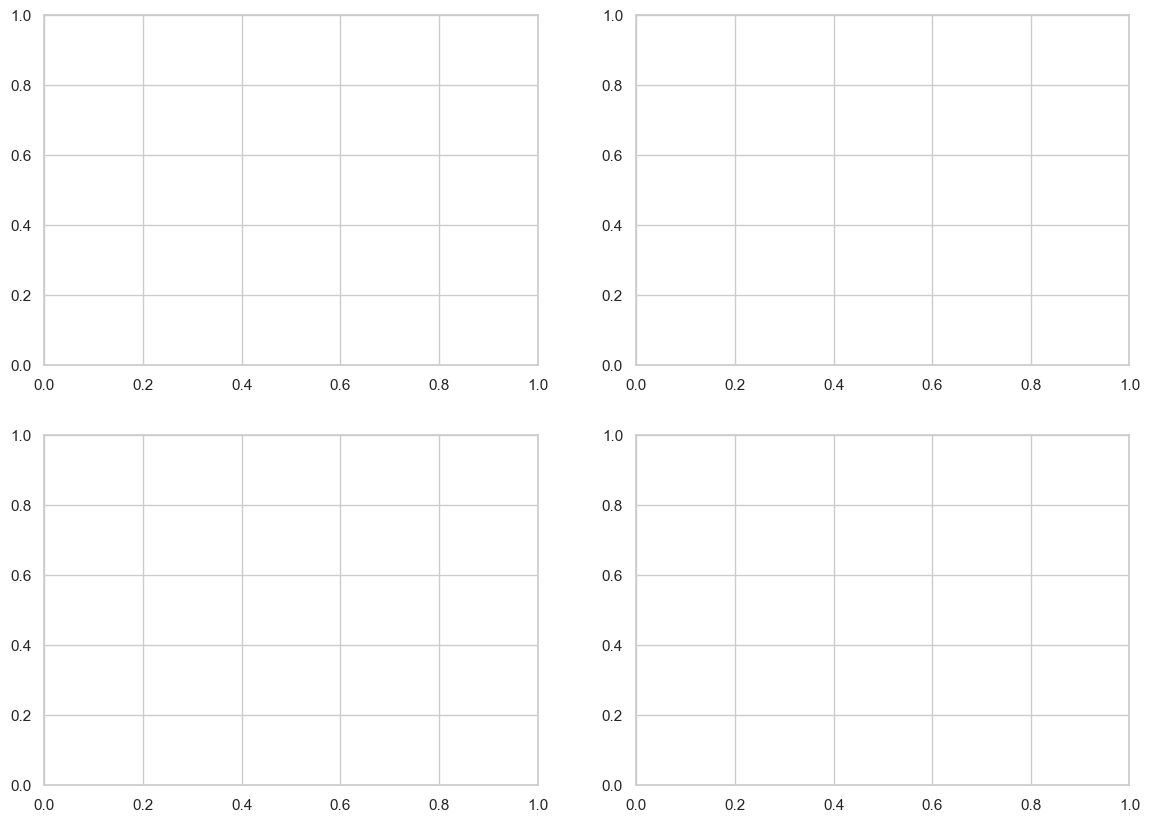

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
print(axes.shape)

In [29]:
# Chart 2: Average Discount vs AOV per Segment
ax2 = axes[0, 1]
ax2_twin = ax2.twinx()
sns.barplot(
    data=segment_summary,
    x="customer_segment",
    y="avg_discount",
    color="#C44E52",
    alpha=0.8,
    ax=ax2,
)
sns.lineplot(
    data=segment_summary,
    x="customer_segment",
    y="aov",
    color="#8172B2",
    marker="o",
    linewidth=2.5,
    ax=ax2_twin,
)
ax2.set_title(
    "Average Discount (Bar) vs AOV (Line)", fontsize=12, fontweight="bold"
)
ax2.set_ylabel("Avg Discount (INR)", color="#C44E52")
ax2_twin.set_ylabel("AOV (INR)", color="#8172B2")
ax2_twin.grid(False)

(2, 2)


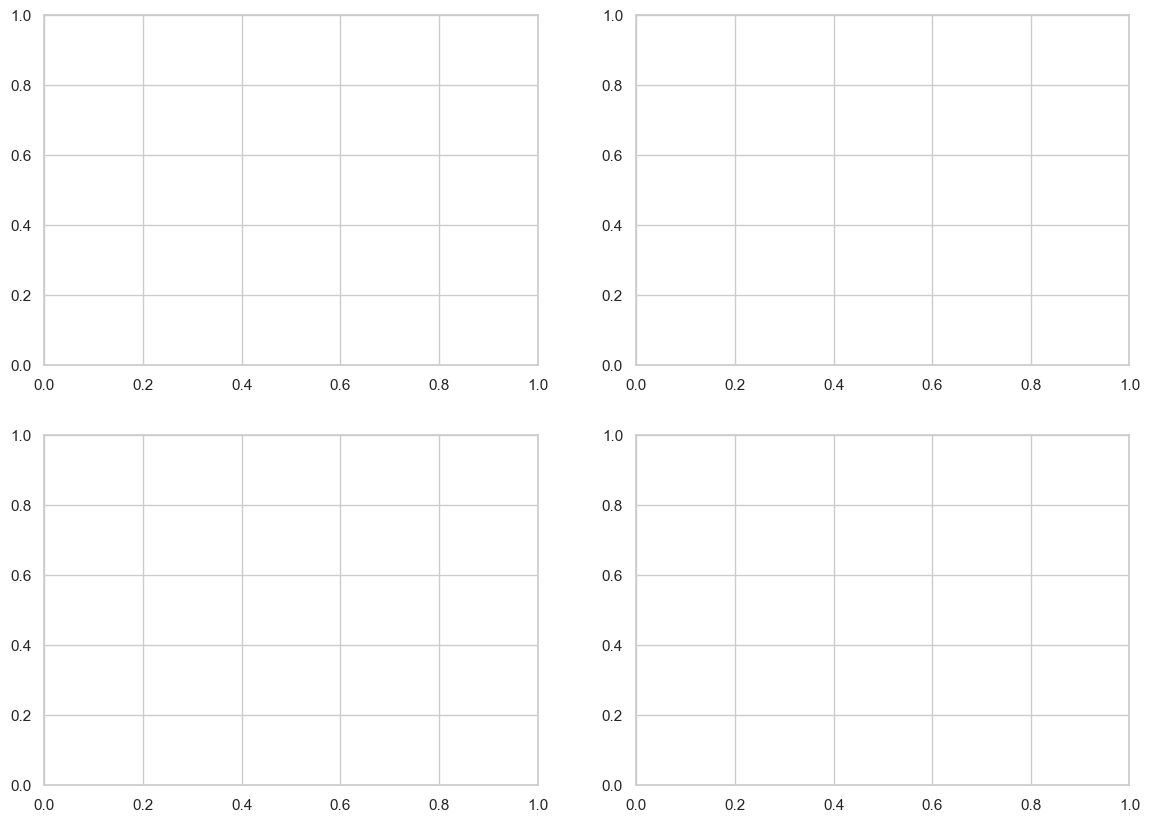

In [28]:
# Chart 3: Basket Size vs Net Revenue across Discount Tiers
discount_tier_melted = discount_tier_analysis.melt(
    id_vars="discount_bracket",
    value_vars=["avg_basket_size", "avg_net_revenue"],
    var_name="Metric",
    value_name="Amount",
)
sns.barplot(
    data=discount_tier_melted,
    x="discount_bracket",
    y="Amount",
    hue="Metric",
    palette="muted",
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    "Basket Size vs Net Revenue per Discount Tier",
    fontsize=12,
    fontweight="bold",
)
axes[1, 0].set_ylabel("Amount (INR)")
axes[1, 0].set_xlabel("Discount Band (INR)")
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
print(axes.shape)

(2, 2)


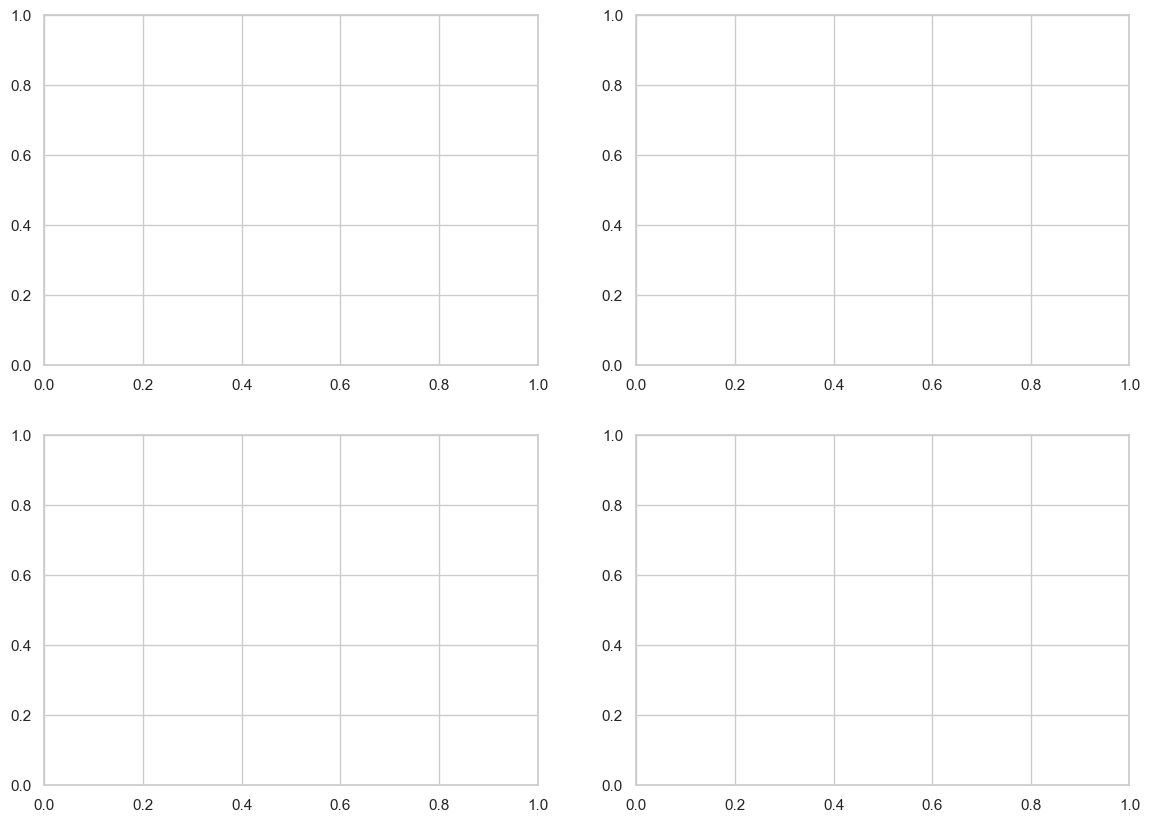

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
print(axes.shape)

In [24]:
print("Test successful")
print(master_data.shape)
print(master_data.columns.tolist())

Test successful
(50, 15)
['order_id', 'customer_id', 'restaurant_id', 'order_date', 'order_status', 'delivery_minutes', 'order_amount', 'discount', 'customer_name', 'city', 'signup_date', 'customer_segment', 'NetRevenue', 'discount_pct', 'discount_bracket']


In [30]:
# Chart 4: Scatter Plot - Order Amount vs Discount
sns.scatterplot(
    data=master_data,
    x="discount",
    y="order_amount",
    hue="customer_segment",
    palette="Set2",
    s=70,
    ax=axes[1, 1],
)
sns.regplot(
    data=master_data,
    x="discount",
    y="order_amount",
    scatter=False,
    color="gray",
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    "Order Amount vs. Discount Given", fontsize=12, fontweight="bold"
)
axes[1, 1].set_xlabel("Discount (INR)")
axes[1, 1].set_ylabel("Gross Order Amount (INR)")

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [31]:
print("Test successful")
print(master_data.shape)
print(master_data.columns.tolist())

Test successful
(50, 15)
['order_id', 'customer_id', 'restaurant_id', 'order_date', 'order_status', 'delivery_minutes', 'order_amount', 'discount', 'customer_name', 'city', 'signup_date', 'customer_segment', 'NetRevenue', 'discount_pct', 'discount_bracket']
